# VEQT vs ATD:  did a single stock over the past year beat the index?
 This notebook compares one individual stock, Alimentation Couche Tarde (ATD.TO) against VEQT, an all equity ETF that holds thousands of companies across the globe. Over the past year, which one gave the better return and overall how much risk (described in day to day volatility) came with it?


In [1]:
import yfinance as yf 
import matplotlib.pyplot as plt 
import warnings
warnings.filterwarnings("ignore", message="The inplace keyword")

In [2]:
veqt = yf.Ticker("VEQT.TO")
veqt_history = veqt.history(period="1y")

In [3]:
atd = yf.Ticker("ATD.TO")
atd_history = atd.history(period="1y")

In [4]:
print("Check same start date:", veqt_history.index[0] == atd_history.index[0])
print("Check same end date:", veqt_history.index[-1] == atd_history.index[-1])
print("Check same length:", len(veqt_history) == len(atd_history))

Check same start date: True
Check same end date: True
Check same length: True


In [5]:
veqt_start_price = veqt_history["Close"].iloc[0]
veqt_end_price = veqt_history["Close"].iloc[-1]
atd_start_price = atd_history["Close"].iloc[0]
atd_end_price = atd_history["Close"].iloc[-1]
atd_simple_returns = (atd_end_price - atd_start_price)/atd_start_price
veqt_simple_returns = (veqt_end_price - veqt_start_price)/veqt_start_price
print("ATD 1 year returns", atd_simple_returns)
print("VEQT 1 year returns", veqt_simple_returns)


ATD 1 year returns 0.1568783879712602
VEQT 1 year returns 0.15514191955629283


In [6]:
veqt_daily = veqt_history["Close"].pct_change()
atd_daily = atd_history["Close"].pct_change()
atd_std = atd_daily.std()
veqt_std = veqt_daily.std()
print("ATD daily standard deviation", atd_std)
print("VEQT daily standard deviation", veqt_std)
print("How much more volatile ATD is compared to VEQT:", atd_std/veqt_std )

ATD daily standard deviation 0.01676441697809847
VEQT daily standard deviation 0.00809004438567237
How much more volatile ATD is compared to VEQT: 2.072228059439153


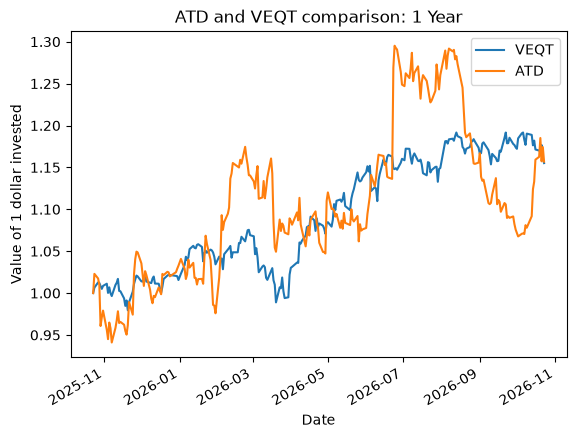

In [7]:
veqt_growth = veqt_history["Close"] / veqt_start_price
atd_growth = atd_history["Close"] / atd_start_price
veqt_growth.plot(label = "VEQT")
atd_growth.plot(label="ATD")
plt.legend()
plt.title("ATD and VEQT comparison: 1 Year")
plt.ylabel("Value of 1 dollar invested")
plt.show()



## Verdict
Over the past year, ATD returned around 15.7% and VEQT returned around 15.5%, so both had very similar return percentages. However ATD was much more volatile and had much larger swings than VEQT; ATD had a daily standard deviation roughly two times VEQT's daily standard deviation. Chart also shows this as you can clearly see that ATD was well ahead of VEQT during the summer then fell behind VEQT in fall. In conclusion, ATD gave roughly the same rewards as the VEQT with twice the risk. So on a risk adjusted basis, this year the VEQT was a better choice to hold then the ATD.
### Limitations
- This metric only covers one year. Doesnt show the full picture and a single stock can beat the index by a large margin in just a single year. A single year cant differentiate luck and skill. 
- It compares only one stock
- Past returns and this information in general cannot predict the future

